## Objective

This EDA establishes the empirical foundation for downstream feature engineering, customer segmentation, and CLV modeling. It targets four areas that carry direct implications for modeling choices and business interpretation:

1. **Revenue trends over time** to map seasonality, growth, and temporal coverage.
2. **Customer revenue concentration** through Pareto analysis to quantify how unevenly value is distributed.
3. **Order size distribution** to characterize typical purchasing patterns and identify skewness that affects modeling choices.
4. **Returns validation** to confirm the cleaning decision from the prior notebook holds under transactional scrutiny.

Each area is examined only to the extent that it informs a specific modeling decision or clarifies a structural feature of the data.

### Outputs

Monthly revenue summaries and customer-level distributions feed directly into Power BI dashboards used to communicate context to stakeholders and align CLV outputs with business-facing reporting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Color palette for visuals
COLOR_PRIMARY = "#2E4057"      # Dark slate blue
COLOR_SECONDARY = "#E67E22"    # Burnt orange
COLOR_ACCENT = "#27AE60"       # Forest green
COLOR_GRID = "#D5D8DC"         # Light grey
COLOR_TEXT = "#2C3E50"         # Dark grey-blue

# Set global matplotlib defaults
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COLOR_TEXT,
    "axes.labelcolor": COLOR_TEXT,
    "text.color": COLOR_TEXT,
    "xtick.color": COLOR_TEXT,
    "ytick.color": COLOR_TEXT,
    "grid.color": COLOR_GRID,
    "grid.alpha": 0.4,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Load cleaned transactions dataset
file_path = "/kaggle/input/online-retail-clean/transactions_clean.csv"

txn_data = pd.read_csv(file_path, parse_dates = ["InvoiceDate"])
print(f"Loaded cleaned transactions: {txn_data.shape}")

txn_data.head()

Loaded cleaned transactions: (804008, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


## Revenue Trends and Customer Activity Over Time

Monthly aggregation surfaces structural patterns in revenue and customer activity while stripping out noise that carries no predictive value. A customer's choice to transact on a Tuesday rather than a Saturday is daily noise. Their total spend over a calendar month is the stable signal that informs long-term value estimation. Monthly granularity retains seasonality, growth trajectories, and shifts in engagement without overfitting to short-term fluctuations.

Four monthly series are computed:

- **Total revenue** to track top-line performance.
- **Order volume** to measure transaction frequency.
- **Unique active customers** to assess engagement breadth.
- **Average order value (AOV)** derived as revenue divided by order count.

These series verify that the transaction timeline is intact - no gaps, no structural breaks - before customer-level modeling begins. They also establish the temporal backdrop against which CLV estimates will later be interpreted, making it possible to distinguish a customer whose spending declined from one who simply transacted during a seasonal trough.

In [ ]:
# Create monthly period for temporal aggregation
txn_data["YearMonth"] = txn_data["InvoiceDate"].dt.to_period("M").astype(str)

# Aggregate to monthly granularity for trend analysis
monthly = txn_data.groupby("YearMonth", as_index = False).agg(
    Revenue = ("TotalPrice", "sum"),
    Orders = ("Invoice", "nunique"),
    Customers = ("CustomerID", "nunique")
)

# Derive AOV as a ratio metric
monthly["AOV"] = monthly["Revenue"] / monthly["Orders"]

monthly.tail()

,YearMonth,Revenue,Orders,Customers,AOV
20,2011-08,623465.360,1269,933,491.304460
21,2011-09,893007.832,1745,1259,511.752339
22,2011-10,971224.120,1910,1359,508.494304
23,2011-11,1120677.180,2640,1659,424.498932
24,2011-12,315017.330,766,611,411.249778


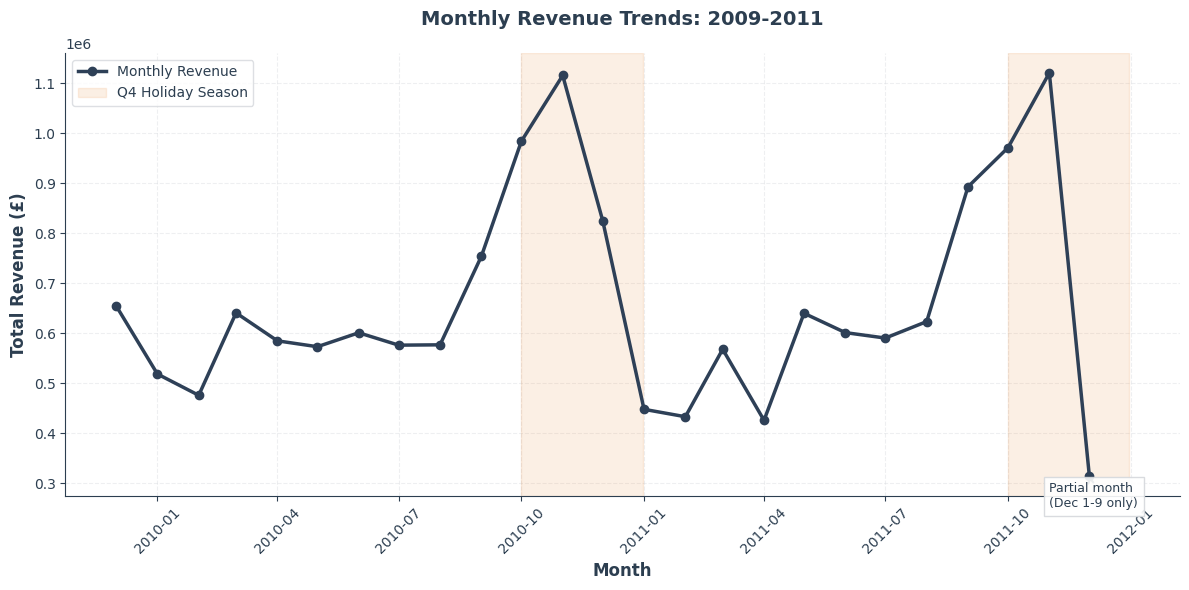

In [3]:
fig, ax = plt.subplots(figsize = (12, 6))

x_values = pd.to_datetime(monthly["YearMonth"])
y_values = monthly["Revenue"]

# Primary revenue trend line
ax.plot(x_values, y_values, 
        marker = 'o', 
        linestyle = '-', 
        color = COLOR_PRIMARY, 
        linewidth = 2.5,
        markersize = 6,
        label = 'Monthly Revenue')

# Shade Q4 periods to highlight seasonal peaks
for year in [2010, 2011]:
    q4_start = pd.to_datetime(f"{year}-10-01")
    q4_end = pd.to_datetime(f"{year}-12-31")
    ax.axvspan(q4_start, q4_end, alpha = 0.12, color = COLOR_SECONDARY, label = 'Q4 Holiday Season' if year == 2010 else None)

ax.set_title("Monthly Revenue Trends: 2009-2011", fontsize = 14, fontweight = 'bold', pad = 20)
ax.set_xlabel("Month", fontsize = 12, fontweight = 'semibold')
ax.set_ylabel("Total Revenue (£)", fontsize = 12, fontweight = 'semibold')
ax.tick_params(axis = 'x', rotation = 45)
ax.grid(True, linestyle = '--', alpha = 0.4)
ax.legend(frameon = True, facecolor = 'white', edgecolor = COLOR_GRID)
ax.set_axisbelow(True)

# Add subtle annotation for the incomplete December 2011 data
ax.annotate('Partial month\n(Dec 1-9 only)', 
            xy = (x_values.iloc[-1], y_values.iloc[-1]),
            xytext = (x_values.iloc[-2], y_values.iloc[-1] * 0.8),
            arrowprops = dict(arrowstyle = '->', color = COLOR_TEXT, lw = 1.5),
            fontsize = 9,
            bbox = dict(facecolor = 'white', edgecolor = COLOR_GRID, alpha = 0.9))

plt.tight_layout()
plt.show()

### Discussion of Monthly Revenue Trends

The monthly revenue trend reveals a consistent seasonal pattern across the observed period. Revenue builds throughout the year, peaks in Q4, and declines sharply at the start of the following year. This pattern appears in both 2010 and 2011, with revenues rising steadily from mid-year and reaching their highest levels in November and December.

The Q4 spikes are consistent with retail behavior driven by holiday demand and promotional activity. The January-February decline reflects post-holiday slowdown in discretionary spending.

Overall revenue levels in late 2011 are comparable to late 2010, suggesting business stability rather than structural growth or decline. The December 2011 drop is partially explained by incomplete data coverage - the dataset ends December 9, 2011, capturing only nine days of the month.

**Modeling implication:** CLV estimates and customer segmentation must account for seasonality when comparing customers acquired or active at different points in the calendar year. A customer who appears inactive in January may simply be following the seasonal pattern.

## Customer Revenue Concentration: Pareto Analysis

In retail and e-commerce, revenue is rarely distributed evenly across the customer base. A small proportion of customers often accounts for a disproportionately large share of total revenue, a pattern described by the Pareto principle. Understanding whether such concentration exists directly influences how retention efforts, loyalty programs, and marketing budgets should be prioritized.

The following analysis quantifies revenue concentration across customers to determine whether CLV-based prioritization can deliver meaningful business impact.

Top 24.2% of customers account for 80% of revenue


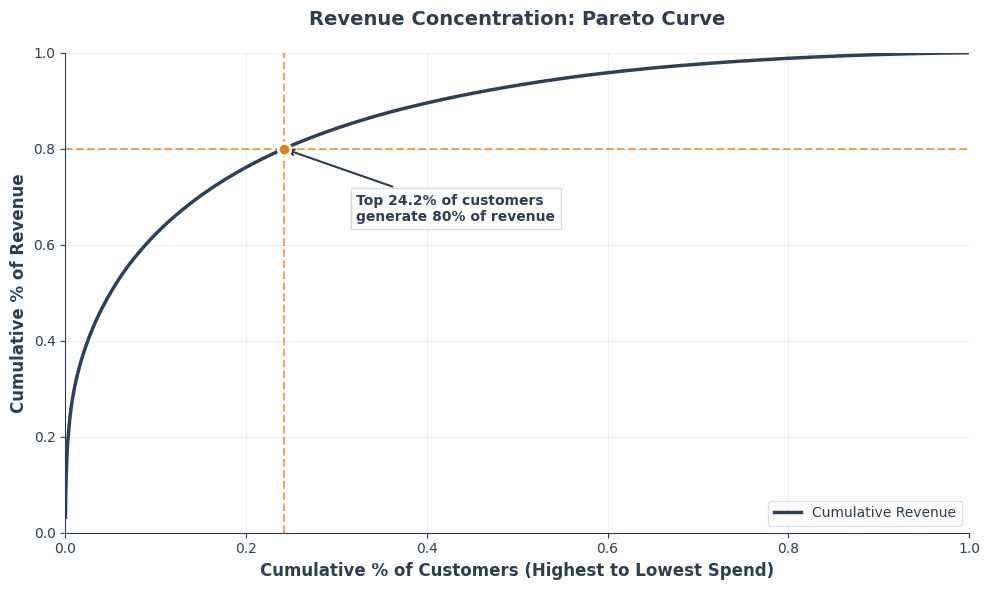

In [4]:
# Aggregate total revenue per customer for concentration analysis
cust_revenue = txn_data.groupby("CustomerID", as_index = False).agg(
    Revenue = ("TotalPrice", "sum")
)

# Sort descending to identify high-value customers first
cust_revenue = cust_revenue.sort_values("Revenue", ascending = False).reset_index(drop = True)

# Calculate cumulative revenue contribution
cust_revenue["cum_rev"] = cust_revenue["Revenue"].cumsum()
cust_revenue["cum_rev_pct"] = cust_revenue["cum_rev"] / cust_revenue["Revenue"].sum()
cust_revenue["cust_pct"] = (np.arange(len(cust_revenue)) + 1) / len(cust_revenue)

# Identify the customer percentage at the 80% revenue threshold
pct80 = cust_revenue.loc[cust_revenue["cum_rev_pct"] >= 0.8, "cust_pct"].iloc[0]
print(f"Top {pct80:.1%} of customers account for 80% of revenue")

# Pareto curve
fig, ax = plt.subplots(figsize = (10, 6))

ax.plot(cust_revenue["cust_pct"], cust_revenue["cum_rev_pct"], 
        linewidth = 2.5, 
        color = COLOR_PRIMARY,
        label = "Cumulative Revenue")

# Threshold lines at 80% revenue
ax.axhline(y = 0.8, color = COLOR_SECONDARY, linestyle = '--', alpha = 0.7, linewidth = 1.5)
ax.axvline(x = pct80, color = COLOR_SECONDARY, linestyle = '--', alpha = 0.7, linewidth = 1.5)

# Intersection point
ax.scatter(pct80, 0.8, color = COLOR_SECONDARY, s = 80, zorder = 5, edgecolor = 'white', linewidth = 2)

# Annotation at intersection
ax.annotate(f'Top {pct80:.1%} of customers\ngenerate 80% of revenue', 
            xy = (pct80, 0.8), 
            xytext = (pct80 + 0.08, 0.65),
            arrowprops = dict(arrowstyle = '->', color = COLOR_TEXT, lw = 1.5),
            fontsize = 10, 
            fontweight = 'bold',
            bbox = dict(facecolor = 'white', edgecolor = COLOR_GRID, alpha = 0.9))

ax.set_title("Revenue Concentration: Pareto Curve", fontsize = 14, fontweight = 'bold', pad = 20)
ax.set_xlabel("Cumulative % of Customers (Highest to Lowest Spend)", fontsize = 12, fontweight = 'semibold')
ax.set_ylabel("Cumulative % of Revenue", fontsize = 12, fontweight = 'semibold')
ax.grid(True, alpha = 0.4)
ax.set_axisbelow(True)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc = "lower right", frameon = True, facecolor = 'white', edgecolor = COLOR_GRID)

plt.tight_layout()
plt.show()

### Discussion of the Pareto Curve

Revenue concentration is pronounced: **24.2% of customers account for 80% of total revenue**. This is less extreme than a strict 80/20 split but still indicates heavily skewed customer value, a pattern consistent with retail businesses where a minority of customers drives the majority of revenue.

**Business implication:** Retaining and nurturing high-value customers will have significantly greater impact on revenue performance than uniformly applied engagement strategies. This finding justifies customer-level prioritization through segmentation and CLV modeling.

**Caveat:** The Pareto result is a descriptive baseline, not a prescriptive rule. Customer value is dynamic, and customers outside the top revenue cohort may represent meaningful future potential. CLV modeling and segmentation build on this analysis by incorporating both historical behavior and forward-looking value.

## Returns Validation

The cleaning notebook established that all negative-quantity rows in this dataset are tied to canceled invoices (prefixed with "C"). Removing cancellations therefore removes all negative quantities. This section validates that decision against the working dataset to confirm no residual returns remain.

This validation is critical: if returns existed as a separate economic event, CLV would need to model net revenue (gross minus returns) rather than gross revenue. The distinction matters for how downstream features are engineered and interpreted.

In [5]:
# Validate that no negative-quantity rows remain after cleaning
returns = txn_data[txn_data["Quantity"] < 0]
print(f"Return rows: {len(returns):,}")
print(f"Return revenue contribution: £{returns['TotalPrice'].sum():,.2f}")
print(f"Return rate: {len(returns) / len(txn_data):.4%}")

Return rows: 0
Return revenue contribution: £0.00
Return rate: 0.0000%


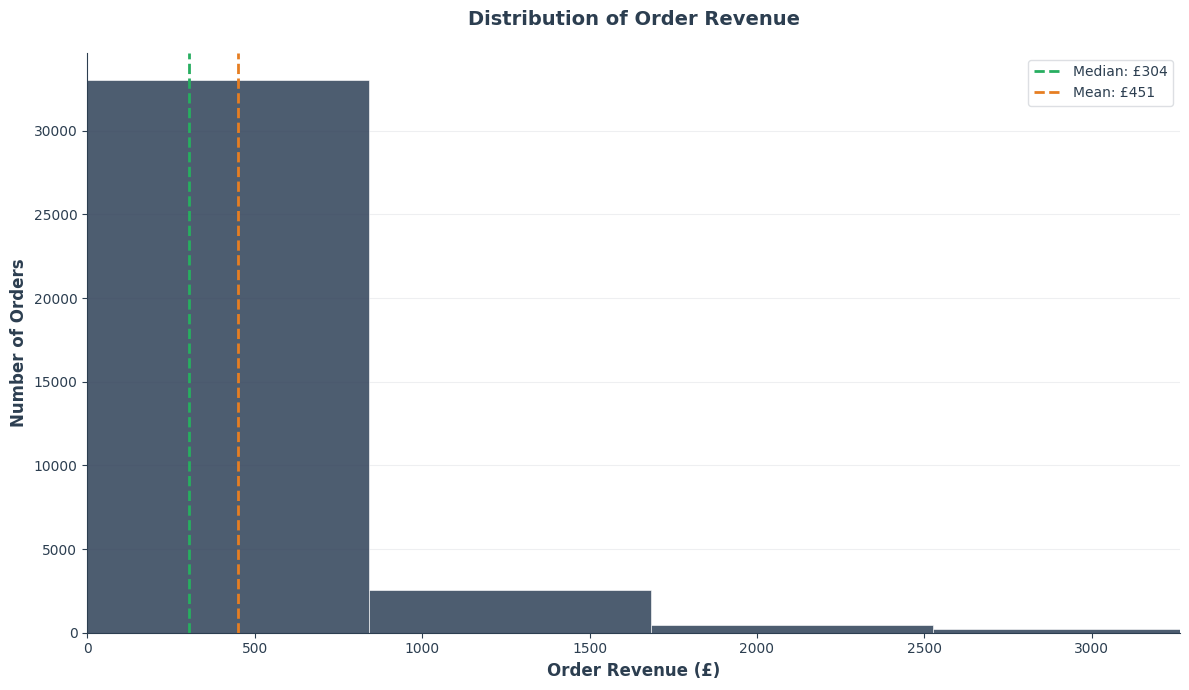

Order count: 36,591
Median order revenue: £303.84
Mean order revenue: £451.29
Skewness: 13.96


In [ ]:
# Order-level revenue distribution for understanding purchase patterns
order_totals = txn_data.groupby("Invoice", as_index = False).agg(
    OrderRevenue = ("TotalPrice", "sum")
)

fig, ax = plt.subplots(figsize = (12, 7))

# Histogram
counts, bins, patches = ax.hist(order_totals["OrderRevenue"], 
                                 bins = 50, 
                                 edgecolor = 'white',
                                 color = COLOR_PRIMARY,
                                 alpha = 0.85,
                                 linewidth = 0.5)

ax.set_title("Distribution of Order Revenue", fontsize = 14, fontweight = 'bold', pad = 20)
ax.set_xlabel("Order Revenue (£)", fontsize = 12, fontweight = 'semibold')
ax.set_ylabel("Number of Orders", fontsize = 12, fontweight = 'semibold')
ax.grid(True, axis = 'y', alpha = 0.4)
ax.set_axisbelow(True)

# Add median and mean reference lines
median_rev = order_totals["OrderRevenue"].median()
mean_rev = order_totals["OrderRevenue"].mean()

ax.axvline(median_rev, color = COLOR_ACCENT, linestyle = '--', linewidth = 2, label = f'Median: £{median_rev:,.0f}')
ax.axvline(mean_rev, color = COLOR_SECONDARY, linestyle = '--', linewidth = 2, label = f'Mean: £{mean_rev:,.0f}')

ax.legend(frameon = True, facecolor = 'white', edgecolor = COLOR_GRID)
ax.set_xlim(0, order_totals["OrderRevenue"].quantile(0.99))

plt.tight_layout()
plt.show()

print(f"Order count: {len(order_totals):,}")
print(f"Median order revenue: £{median_rev:,.2f}")
print(f"Mean order revenue: £{mean_rev:,.2f}")
print(f"Skewness: {order_totals['OrderRevenue'].skew():.2f}")

## Order Revenue Distribution: Discussion

The order revenue distribution is heavily right-skewed: most orders are small-to-mid-value, with a long tail of larger baskets. The median order value is substantially lower than the mean, confirming that a small number of high-value orders pull the average upward.

This skewness has direct implications for CLV modeling:

- **Monetary value estimation** must account for heavy-tailed distributions.
- **Outlier handling** in feature engineering should use robust methods (percentiles, log transforms).
- **Model evaluation** should report median absolute error alongside mean metrics, as the mean is sensitive to high-value outliers.

The pattern is typical of e-commerce: many low-to-mid-value orders from individual consumers, with fewer high-value purchases from bulk buyers or business customers.

## Exporting Monthly Revenue for BI Storytelling

The monthly revenue summary is exported to support downstream visualization in Power BI. Persisting this aggregated view enables consistent reporting of revenue trends, order activity, and customer engagement across dashboards while ensuring alignment between notebook analysis and business-facing reporting.

This separation allows exploratory analysis to remain flexible in Python while standardized metrics are presented to stakeholders through Power BI.

In [7]:
file_name = "monthly_summary.csv"

monthly.to_csv(file_name, index = False)
print(f"Monthly summaries saved to: {file_name}")

Monthly summaries saved to: monthly_summary.csv
